Dawson Conlon

Ricky Doucette

In [ ]:
#Import libraries
import pathlib as path
import numpy as np
import pandas as pd
import random as rand
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
from sklearn import cluster
import hdbscan as hd

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.sparse import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.datasets import fetch_openml
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

## <font color='lightblue'>1. Data Understanding </font>

In [13]:
#Naming the csv files to a pandas dataframe
customers = pd.read_csv("/content/customer_master-selected-columns.csv")
orders = pd.read_csv("/content/order_items.csv")
sales = pd.read_csv("/content/ecommerce_sales_customer_analytics_150k.csv")
products = pd.read_csv("/content/product_catalog.csv")

# Merge the relivent tables

In [14]:
#Combining orders table and product table
orders_prods= orders.merge(
products.drop(columns=['product_cost']),
on=['product_id','unit_price'],
how='inner'
)

#Merge the sales and orders_prods data and only keep features of interest
shipping = sales[[ 'order_id', 'customer_rating', 'customer_segment', 'customer_lifetime_value','warehouse', 'estimated_delivery_days', 'delivery_days', 'shipping_method', 'delivery_status','customer_order_count']].merge(
    orders_prods[['order_id', 'quantity', 'profit', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost']],
    on='order_id',
    how='inner'
)

In [15]:
shipping.columns

Index(['order_id', 'customer_rating', 'customer_segment',
       'customer_lifetime_value', 'warehouse', 'estimated_delivery_days',
       'delivery_days', 'shipping_method', 'delivery_status',
       'customer_order_count', 'quantity', 'profit', 'gross_sales',
       'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales',
       'product_cost'],
      dtype='object')

In [16]:
#Take a look at the data types
shipping.dtypes

,0
order_id,object
customer_rating,float64
customer_segment,object
customer_lifetime_value,float64
warehouse,object
estimated_delivery_days,float64
delivery_days,float64
shipping_method,object
delivery_status,object
customer_order_count,int64


## Determine the types of data we are dealing with

### Catagorical
    warhouse
    shipping_method
    delivery_status
    customer_segment

### Numerical
    estimated_delivery_days
    delivery_days
    quantity
    profit
    gross_sales
    discount_amount
    tax_amount
    shipping_cost
    net_sales
    product_cost
    customers_lifetime_value
    customer_rating
    customer_order_count

### Identifers
    order_id
    customer_id

In [17]:
#Handle missing values
shipping.isna().sum()

,0
order_id,0
customer_rating,70541
customer_segment,0
customer_lifetime_value,0
warehouse,0
estimated_delivery_days,70541
delivery_days,70541
shipping_method,0
delivery_status,0
customer_order_count,0


We have some missing values for estimated_delivery_days and delivery_days because some orders where canceled


Because we are only concerned with orders that have been delivered we are going to drop rows that have had their orders canceled

In [18]:
shipping_df_clean = shipping.dropna(how = 'any')

In [19]:
shipping_df_clean.isna().sum()

,0
order_id,0
customer_rating,0
customer_segment,0
customer_lifetime_value,0
warehouse,0
estimated_delivery_days,0
delivery_days,0
shipping_method,0
delivery_status,0
customer_order_count,0


### Summary Statistics of Key Variables

In [20]:
#Descriptive statistics on shippign cost
shipping_df_clean["shipping_cost"].describe()

,shipping_cost
count,327028.000000
mean,8.407856
std,6.772277
min,0.000000
25%,3.380000
50%,5.870000
75%,12.460000
max,36.460000


In [21]:
#Descriptive statstics on delivery days
shipping_df_clean["delivery_days"].describe()

,delivery_days
count,327028.000000
mean,4.554130
std,2.812564
min,0.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,14.000000


In [22]:
#Calculate the median shipping cost
median_ship = shipping_df_clean['shipping_cost'].median()

print(f"The medain cost of a shipment for all deliveries is {median_ship} $.")

The medain cost of a shipment for all deliveries is 5.87 $.


In [23]:
#Calculate the median days to deliver
median_delivery_days = shipping_df_clean['delivery_days'].median()

print(f"The median days it takes to deliver a package for all deliveries is {median_delivery_days} days.")

The median days it takes to deliver a package for all deliveries is 4.0 days.


## Interpretation

### For the shipping cost;

    Based on a count of 327,028 shipments

    On average it cost 8.40$ per shipment

    The median cost of a shipment was 5.87$
    
    There is a standard deveation of 6.8$

    The cheapest shipment was 0$ (free)

    The most expensive shipment was 36.46$



### For the delivery_days cost;

    Based on a count of 327,028 shipments

    On average it took 4.6 days to deliver a shipment

    The median time to deliver a shipment was 4.0 days
    
    There is a standard deveation of 2.8 days

    The quickest shipment was 0 (same day)

    The longest shipment was 14.0 days

## <font color='lightblue'>2. Data Exploration and Visualization </font>

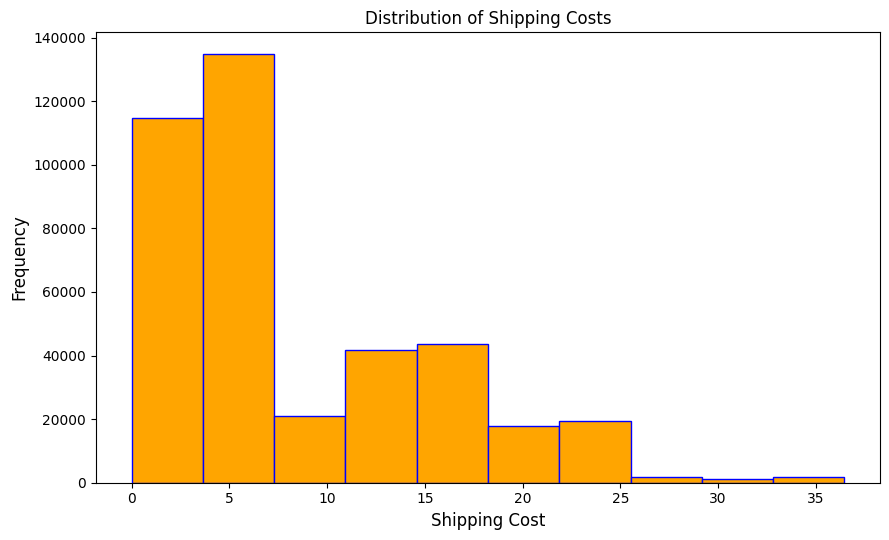

In [39]:
# Distribution of shipping cost
#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a histogram of shipping cost and frequency
plt.hist(
    shipping['shipping_cost'],
    edgecolor = 'blue',
    color = 'orange')

#Add labels
plt.xlabel('Shipping Cost',fontsize = 12)
plt.ylabel('Frequency',fontsize = 12)
plt.title('Distribution of Shipping Costs',fontsize = 12)

plt.tight_layout()
plt.show()

Interpretaion

The distribution of shipping cost is right skewed, with cheaper shipments being more common.

Histogram

1. Data Component

Shipping cost is a numerical continuous variable.

2. Graphical Component

A histogram is best suited for viewing the shape of the distribution of a variable.

3. Label Component

As is customary for a histogram the a-axis contains the variable of interest with the y-axis containing frequency count. The continuous valued shipping cost is placed in discrete bins to give shape to the distribution.

4. Esthetic Component

The plot shows the height of each bin as a frequency in order to fill in the shape of the distribution of the variable of interest, shipping cost. It is a simple visual to determine whether the distribution is normal, skewed, etc. In this case there is a bimodal distribution with most of the data around 5 dollars and a second smaller peak around 15 dollars.


5. Ethical Component

The shape of the distribution can appear different for various choices of bin width.


### Variable 2: Net Sales

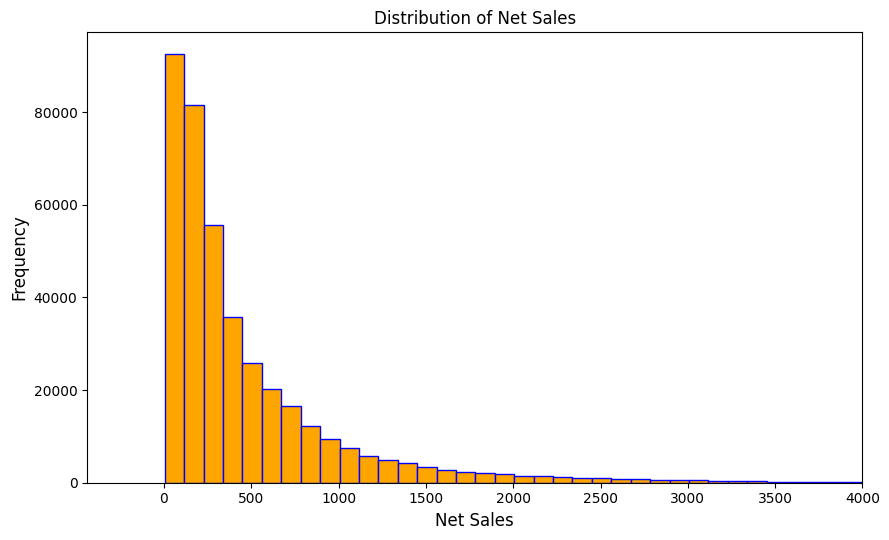

In [45]:
# Distribution of Net Sales
#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a histogram of shipping cost and frequency
plt.hist(
    shipping['net_sales'],
    edgecolor = 'blue',
    color = 'orange',
    bins = 80)

#Set X-limit
plt.xlim(right = 4000)

#Add labels
plt.xlabel('Net Sales',fontsize = 12)
plt.ylabel('Frequency',fontsize = 12)
plt.title('Distribution of Net Sales',fontsize = 12)

plt.tight_layout()
plt.show()

Histogram

1. Data Component

Net sales is a numerical continuous variable.

2. Graphical Component

A histogram is best suited for viewing the shape of the distribution of a variable.

3. Label Component

As is customary for a histogram the a-axis contains the variable of interest with the y-axis containing frequency count. The continuous valued net sales is placed in discrete bins to give shape to the distribution.

4. Esthetic Component

The plot shows the height of each bin as a frequency in order to fill in the shape of the distribution of the variable of interest, net sales. It is a simple visual to determine whether the distribution is normal, skewed, etc. In this case the data is right skewed with most of the net sales being less than 500$.

5. Ethical Component

The binwidth and X-limits where set to not give misleading visual interpretations.

Interpretation

The distribution of net sales is right skewed, with lower sale frequencies beign more common.

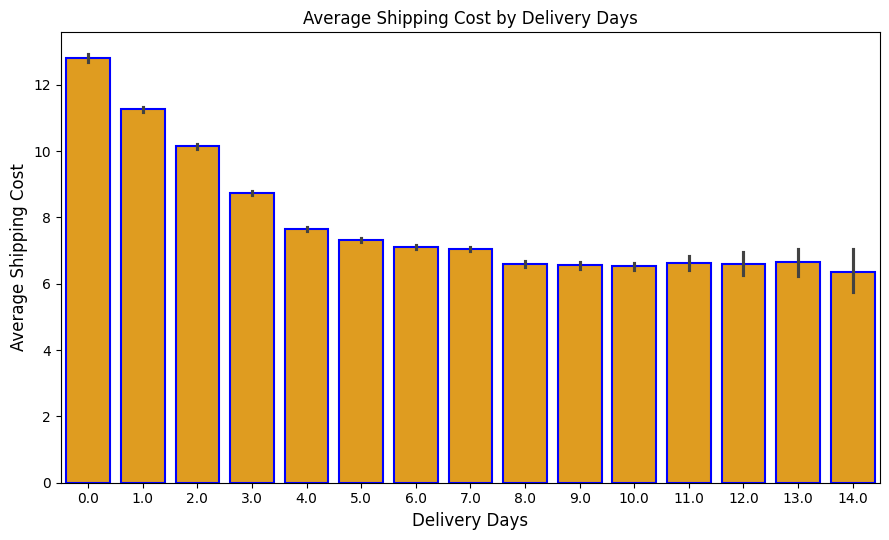

In [25]:
avg_cost = shipping_df_clean.groupby('delivery_days')['shipping_cost'].mean()

#Set the figure size
plt.figure(figsize=(9, 5.5))

#Make a bar plot of the average cost of shipping
sns.barplot(data = shipping_df_clean,
            x = 'delivery_days',
            y = 'shipping_cost',
            color = 'orange',
            edgecolor = 'blue',
            linewidth = 1.5)

#Add labels
plt.xlabel('Delivery Days', fontsize = 12)
plt.ylabel('Average Shipping Cost', fontsize = 12)
plt.title('Average Shipping Cost by Delivery Days', fontsize = 12)


#Use tight layout to ensure there is no overlap
plt.tight_layout()
plt.show()

Bar Chart

1. Data Component

Average shipping cost in dollars is a continuous numerical variable.
Days taken for delivery is a discrete numerical variable.

2. Graphical Component

A bar chart or a box plot would be the best visualizations to describe the data, we went with a bar chart because it easily showed where the data plateaus and how many days it usually takes this company to ship a package.

3. Label Component

The x-axis label contains the units days, the y-axis label contains the units, dollars, and quantity of measure average shipping cost.

4. Esthetic Component

The plot is trying to capture the question if a customer pays more for shipping, do they get the shipment in a shorter amount of time? The best way to convey this is to make a chart that one can look at and instantly answer that question our bar chart accomplishes this because you look at the bars for 0 to 2 delivery days and you clearly see on average customers paid more to get that quicker shipping.

5. Ethical Component

I do not think that this graph is misleading although there is some context that is left out such as what items are being delivered that take longer maybe electronics take longer to deliver than other items and having a plot that could capture those categories of items and how long they take to deliver could be insightful.

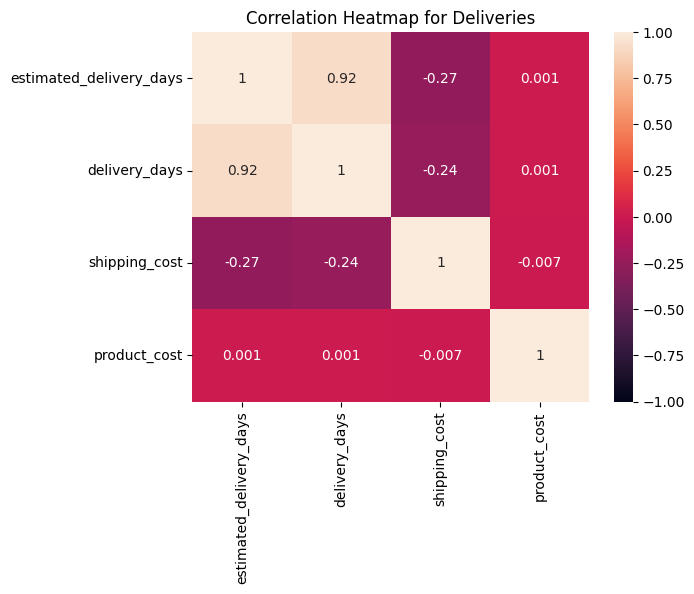

In [28]:
ship_corr = shipping_df_clean[['estimated_delivery_days','delivery_days','shipping_cost','product_cost']].corr().round(3)
sns.heatmap(ship_corr, annot =True, vmin=-1, vmax=1)
plt.title('Correlation Heatmap for Deliveries')
plt.show()


The only variables with a strong correlation is estimated delivery days and delivery days with a correlation coefficient of 0.92. This makes sense intuitively as the company's actual delivery time won't differ too much from their estimated delivery time.

There is a weak negative correlation between shipping cost and both estimated delivery days and delivery days of -0.27 and -0.24. Again it makes sense there is a negative correlation here because usually companies have an option to pay more on shipping for quicker delivery.

Beyond that all the other variables have a negligible correlation to each other.

# Data Pre - Processing

In [29]:
#drop order id
shipping_df_clean = shipping_df_clean.drop(columns=['order_id'])

In [30]:
#Encode the catagorical variables
shipping_encoder = LabelEncoder()

#Warhouse
shipping_df_clean['warehouse'] = shipping_encoder.fit_transform(shipping_df_clean['warehouse'])

# shipping method
shipping_df_clean['shipping_method'] = shipping_encoder.fit_transform(shipping_df_clean['shipping_method'])

#delivery status
shipping_df_clean['delivery_status'] = shipping_encoder.fit_transform(shipping_df_clean['delivery_status'])

#customer segment
shipping_df_clean['customer_segment'] = shipping_encoder.fit_transform(shipping_df_clean['customer_segment'])

In [31]:
shipping_df_clean.head()

,customer_rating,customer_segment,customer_lifetime_value,warehouse,estimated_delivery_days,delivery_days,shipping_method,delivery_status,customer_order_count,quantity,profit,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost
0,3.5,1,12459.68,2,3.0,3.0,3,2,11,2,172.12,488.80,166.00,22.60,6.48,351.88,173.28
1,3.5,1,12459.68,2,3.0,3.0,3,2,11,3,172.92,861.39,311.89,38.47,5.55,593.52,415.05
2,3.6,2,13032.48,4,10.0,10.0,0,2,11,4,-65.84,3019.20,1413.89,305.01,9.00,1919.32,1976.16
3,3.6,2,13032.48,4,10.0,10.0,0,2,11,4,43.37,125.44,42.17,15.82,0.00,99.09,55.72
4,4.3,2,6159.44,14,3.0,3.0,1,2,6,3,12.53,18.93,1.70,1.21,0.98,19.42,5.91


# Build The Model

In [32]:
#Split the data into trainign and testing
#X = shipping_df_clean.drop(columns=['shipping_cost'],axis=1)
X = shipping_df_clean.drop('shipping_cost',axis = 1)

y = shipping_df_clean['shipping_cost']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
#Make a Linear Regression model
LR_shipping = LinearRegression()

LR_shipping.fit(X_train, y_train)

y_predict = LR_shipping.predict(X_test)

#Measure the performance

In [34]:
#Get the R2 score
r2_score(y_test, y_predict)

1.0

R squared was the measurment used, it explains the variation in the response variable due to our model.

With a R squared score of exactly 1.0, we have 100% of our variation in shipping cost explained by our linear regression model. This could be due to overfitting, but we will test whether or not we have an exact mathmatical calculation of shipping cost happening in our model.

We will see if any of the features are direclty used to calculate shipping cost

In [35]:
shipping_df_clean.corr(numeric_only=True)['shipping_cost'].sort_values()

,shipping_cost
estimated_delivery_days,-0.268131
delivery_days,-0.243900
customer_segment,-0.167375
tax_amount,-0.044784
shipping_method,-0.025003
customer_rating,-0.022041
discount_amount,-0.018133
quantity,-0.014454
gross_sales,-0.007107
customer_lifetime_value,-0.007026


There does not seem to be any features that are 100% correlated with shipping cost so there is not one feature that explains 100% of the variation in the shipping cost.

Due to the R2 scoring 1.0, there are features within the data that can be used to directly calculate shipping cost.

In [36]:
#Show the coefficent of the linear reggression model
coef_df = pd.DataFrame({
    'Features': X.columns,
    'Coefficent': LR_shipping.coef_ #Calculate coefficent
}).sort_values(by='Coefficent', ascending=False)

print(coef_df)

                   Features    Coefficent
14                net_sales  1.000000e+00
12          discount_amount  4.000000e-01
9                  quantity  6.579311e-14
1          customer_segment  5.127062e-14
4   estimated_delivery_days  9.723078e-16
2   customer_lifetime_value  2.818926e-17
3                 warehouse -4.765479e-16
6           shipping_method -8.218017e-16
7           delivery_status -1.273016e-15
5             delivery_days -3.087645e-15
0           customer_rating -1.873415e-14
8      customer_order_count -4.231678e-14
13               tax_amount -4.000000e-01
11              gross_sales -4.000000e-01
15             product_cost -6.000000e-01
10                   profit -6.000000e-01


Due to net sales coefficient being equal to 1 and our model R squared equaling 1, we can tell that shipping cost can be mathmatically reconstructed from net sales and some other features.

# Calculate Feature Importance

In [37]:
#Get the permutation importance
importance = permutation_importance(LR_shipping,
                                    X_test,
                                    y_test,
                                    random_state=42)

#Store values in df
feature_importance = pd.DataFrame({
    'Features': X.columns,
    'Importance': importance.importances_mean
}).sort_values(by='Importance', ascending=False)



#Sort the df
feature_importance = feature_importance.sort_values(by='Importance',
                                                    ascending=False)

#Print the df
print(feature_importance)


                   Features    Importance
14                net_sales  16156.077472
11              gross_sales   3296.915575
15             product_cost   2555.737026
10                   profit   1009.839064
12          discount_amount    280.588209
13               tax_amount     34.640510
0           customer_rating      0.000000
1          customer_segment      0.000000
7           delivery_status      0.000000
6           shipping_method      0.000000
5             delivery_days      0.000000
4   estimated_delivery_days      0.000000
3                 warehouse      0.000000
2   customer_lifetime_value      0.000000
8      customer_order_count      0.000000
9                  quantity      0.000000


From this we can see not only that net sales is relied on heavily to calculate shipping cost, but it shows us exactly which features are being used to calculate shipping cost directly and which features are not being used at all.
From this and our R squared of exactly 1.0 we can infer that there is a formula using some combination of the features net sales, gross sales, product cost, profit, discount amount, and tax amount to calculate shipping cost.

# Investigation

# Make a model without net sales

In [38]:
#Set up X and y
shipping_df_temp = shipping_df_clean.drop(columns = ["net_sales"])
X_no_netsales = shipping_df_temp.drop(columns=['shipping_cost'], axis=1)
y_no_netsales = shipping_df_temp['shipping_cost']

#Train the model
X_train_no_netsales, X_test_no_netsales, y_train_no_netsales, y_test_no_netsales = train_test_split(X_no_netsales,
                                                                                                    y_no_netsales,
                                                                                                    test_size=0.2,
                                                                                                    random_state=42)
#Set up Linear Reggresion
LR_shipping_no_netsales = LinearRegression()
LR_shipping_no_netsales.fit(X_train_no_netsales, y_train_no_netsales)

#Predict
y_predict_no_netsales = LR_shipping_no_netsales.predict(X_test_no_netsales)

#Get the R2 score
r2_score(y_test_no_netsales, y_predict_no_netsales)

0.11041403650893966

With the lower R2 score in the above model that does not have net sales feature we can see how difficult it is to predict how much it will cost to ship a product without the model directly calculating it from net sales.

# Discusion

The model achieves perfect predictive performance on the test data, with an R² of 1.0. There are multiple financial features that, when combined, can be used to exactly calculate shipping cost. This makes sense because we know shipping cost is used in the calculation of profit, meaning the equation can be rearranged to solve for shipping cost using the other financial variables. This relationship is also reflected in the model: net sales has an unusually high permutation importance of 16,156 and a regression coefficient of exactly 1.0. When net sales is removed from the model, R² drops from 1.0 to 0.1104, demonstrating how heavily the model relies on net sales and its relationships with the other financial variables. Although the original model has an R² of 1.0 on the test data, this does not necessarily indicate overfitting. Instead, the perfect performance can be explained by the exact mathematical relationships among the financial variables used to predict shipping cost. We can see based off the coefficients and the permutation importance that the only features used for the calculation of shipping are net sales, discount amount, tax amount, gross sales, product cost, and profit.  The other features don’t contribute to the model.  Due to our model’s perfect performance, if given all the features to mathematically calcualte shipping, it would predict unseen data perfectly.